# Measured importance–latency distributions

Compare Paper and Tiles using the recorded masks and timings from
[03_02](03_02_measure_latency.ipynb). Budgets are matched by requested row fraction;
Paper may select fewer rows. Retained importance is the selected percentage of
captured activation importance.

In [43]:
from math             import ceil
from pathlib          import Path
from matplotlib.lines import Line2D

import json

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

Keep selection, reader I/O, and wall time as separate columns, in ms.
Compute each column's median over repetitions, then join the mask metadata.

Selection builds the row mask, including Paper's GPU sort and score transfers.
Reader I/O includes thread startup, reads, alignment copies, and thread joining.
Wall time spans selection through the CPU read's return, including read preparation.
Its median is measured separately, not obtained by adding component medians.
GPU weight transfer and model execution are outside these intervals.

In [44]:
METRICS = ["selection_ms", "io_ms", "wall_ms"]
PAPER   = "Paper greedy (GPU sort)"

In [45]:
cases       = pd.read_csv("cases.csv", float_precision="round_trip")
timings     = pd.read_csv("timings.csv", float_precision="round_trip")
environment = json.loads(Path("environment.json").read_text())

In [46]:
# One metadata row and one sample per case and repetition.
assert cases.case_id.is_unique
assert not timings.duplicated(["case_id", "repeat"]).any()
assert set(timings.case_id) == set(cases.case_id)

repeats = timings.groupby("case_id").size()
assert repeats.eq(environment["repeats"]).all()

for metric in METRICS:
    latency = timings[metric]
    assert np.isfinite(latency).all() and (latency > 0).all()

In [47]:
medians = timings.groupby("case_id")[METRICS].median()

results = cases.join(
    medians,
    on       = "case_id",
    validate = "one_to_one",
)

In [48]:
results = results.rename(columns={
    "tile_rows"    : "tile_width",
    "retained_pct" : "retained",
})

# Profile boundary: KiB -> rows.
row_kib  = results.d * environment["dtype_bytes"] / 1024
boundary = environment["tile_boundary_kib"]
results["saturation_rows"] = boundary / row_kib

assert not results.duplicated(["n", "d", "method", "fraction", "trace_id"]).any()

## 2. Trace summaries

Group cases by shape, method, and requested budget. Compute marginal medians
of each time metric and retained importance across traces, with equal weight per trace.
Check that methods contain the same budgets and trace IDs.

In [49]:
class TracePoints:
    def __init__(self, rows):
        self.samples = (
            rows.set_index("trace_id")[METRICS + ["retained"]]
            .sort_index()
        )

        self.median = self.samples.quantile(0.5)

In [50]:
class MethodResults:
    def __init__(self, rows):
        self.tile_width = rows.tile_width.iloc[0]
        self.budgets    = {}

        for fraction, group in rows.groupby("fraction"):
            self.budgets[fraction] = TracePoints(group)

    def median_curve(self):
        medians = {}

        for fraction, group in self.budgets.items():
            medians[fraction] = group.median

        return pd.DataFrame.from_dict(medians, orient="index")

    def assert_comparable_to(self, baseline):
        assert self.budgets.keys() == baseline.budgets.keys()

        for fraction, group in self.budgets.items():
            current_index  = group.samples.index
            baseline_index = baseline.budgets[fraction].samples.index

            assert current_index.equals(baseline_index)

    def difference_from(self, baseline):
        self.assert_comparable_to(baseline)
        differences = {}

        for fraction, group in self.budgets.items():
            reference = baseline.budgets[fraction].samples
            differences[fraction] = group.samples - reference

        return pd.concat(differences, names=["fraction"])

In [51]:
class ShapeResults:
    def __init__(self, shape, rows):
        self.shape           = shape
        self.saturation_rows = rows.saturation_rows.iloc[0]
        self.trace_count     = rows.trace_id.nunique()

        # Baselines, then decreasing tile width
        groups = rows.groupby("method")

        widths = groups.tile_width.first()
        widths = widths.sort_values(
            ascending   = False,
            na_position = "first",
        )

        self.methods = {}

        for name in widths.index:
            method_rows = groups.get_group(name)
            self.methods[name] = MethodResults(method_rows)

In [52]:
points = {}

for shape, rows in results.groupby(["n", "d"]):
    points[shape] = ShapeResults(shape, rows)

In [53]:
points[(896, 896)].methods[PAPER].budgets[0.5].samples.head()

,selection_ms,io_ms,wall_ms,retained
trace_id,,,,
0,1.041586,0.385084,1.508930,57.780937
14,1.050042,0.419539,1.482185,54.656250
31,1.195884,0.362011,1.629610,63.955133
45,1.183451,0.389292,1.597946,61.605504
63,1.032519,0.381613,1.444379,59.007767


In [54]:
# Matched budgets and traces
for result in points.values():
    baseline = result.methods[PAPER]

    for method in result.methods.values():
        method.assert_comparable_to(baseline)

## 3. Plots by timing metric

Each timing metric has its own figures, with the same traces and budgets.
Points show trace observations; color identifies the requested fraction.
Solid lines connect marginal medians in budget order. The dotted line shows
Paper's median for that metric. These summaries do not define a Pareto frontier.

Baseline/coarse and fine panels use separate logarithmic time ranges
and a common importance range. At 100% budget, every method bypasses selection;
its recorded selection time is only the branch and timing overhead.

In [55]:
latency_labels = {
    "selection_ms" : "Row selection time (ms)",
    "io_ms"        : "Reader I/O time (ms)",
    "wall_ms"      : "Selection + read wall time (ms)",
}

In [56]:
color_scale = plt.cm.ScalarMappable(
    norm = plt.Normalize(results.fraction.min(), results.fraction.max()),
    cmap = "viridis",
)

def draw_observations(ax, method, metric):
    for fraction, group in method.budgets.items():
        samples = group.samples
        ax.scatter(
            samples[metric],
            samples.retained,
            color = color_scale.to_rgba(fraction),
            s     = 9,
            alpha = 0.16,
        )

def draw_median_curve(ax, method, metric):
    curve = method.median_curve()
    ax.plot(
        curve[metric],
        curve.retained,
        color = "black"
    )
    ax.scatter(
        curve[metric],
        curve.retained,
        c          = color_scale.to_rgba(curve.index),
        edgecolors = "black",
        zorder     = 3,
    )

def draw_method(ax, method, metric, baseline=None):
    if baseline is not None:
        ax.plot(
            baseline[metric],
            baseline.retained,
            ":",
            color = "gray"
        )

    draw_observations(ax, method, metric)
    draw_median_curve(ax, method, metric)

In [57]:
def draw_legend(fig):
    reference = Line2D(
        (), (),
        label = "Paper median",

        color     = "gray",
        linestyle = ":",
    )

    observations = Line2D(
        (), (),
        label = "Trace observations",

        color      = "gray",
        linestyle  = "none",
        marker     = "o",
        markersize = 3,
        alpha      = 0.16,
    )

    medians = Line2D(
        (), (),
        label = "Marginal medians",

        color = "black",
    )

    fig.legend(
        handles = (reference, observations, medians),
        loc     = "outside lower center",
        ncol    = 3,
    )

In [58]:
def draw_shape(result, metric):
    n, d     = result.shape
    s        = result.saturation_rows
    methods  = result.methods
    baseline = methods[PAPER].median_curve()

    ncols = 4
    nrows = ceil(len(methods) / ncols)
    fig   = plt.figure(figsize=(4 * ncols, 3 * nrows), layout="constrained")

    shared_x = {}

    for position, (name, method) in enumerate(methods.items(), 1):
        B = method.tile_width

        # Panel settings
        if pd.isna(B):
            title      = name
            axis_group = "baseline/coarse"
        elif B < s:
            title      = f"{name}\nB = {B:g} (< s)"
            axis_group = "fine"
        else:
            title      = f"{name}\nB = {B:g} (≥ s)"
            axis_group = "baseline/coarse"

        reference = None
        if name != PAPER:
            reference = baseline

        # Panel
        ax = fig.add_subplot(
            nrows, ncols, position,
            sharex = shared_x.get(axis_group),
        )
        shared_x[axis_group] = ax

        draw_method(
            ax, method, metric,
            baseline = reference,
        )
        ax.set(
            title  = title,
            xscale = "log",
            ylim   = (0, 102),
            xlabel = latency_labels[metric],
        )

    # Shared guides
    draw_legend(fig)
    fig.colorbar(color_scale, ax=fig.axes, label="Requested fraction")
    fig.supylabel("Retained importance (%)")

    title    = f"{n} x {d} · {result.trace_count} traces · s = {s:.2f} rows"
    subtitle = "Baseline/coarse and fine panels use separate log-latency ranges"
    fig.suptitle(f"{latency_labels[metric]} · {title}\n{subtitle}")
    return fig

### 3.1 Row selection time

Time to construct the selected row mask from prepared CPU importance.

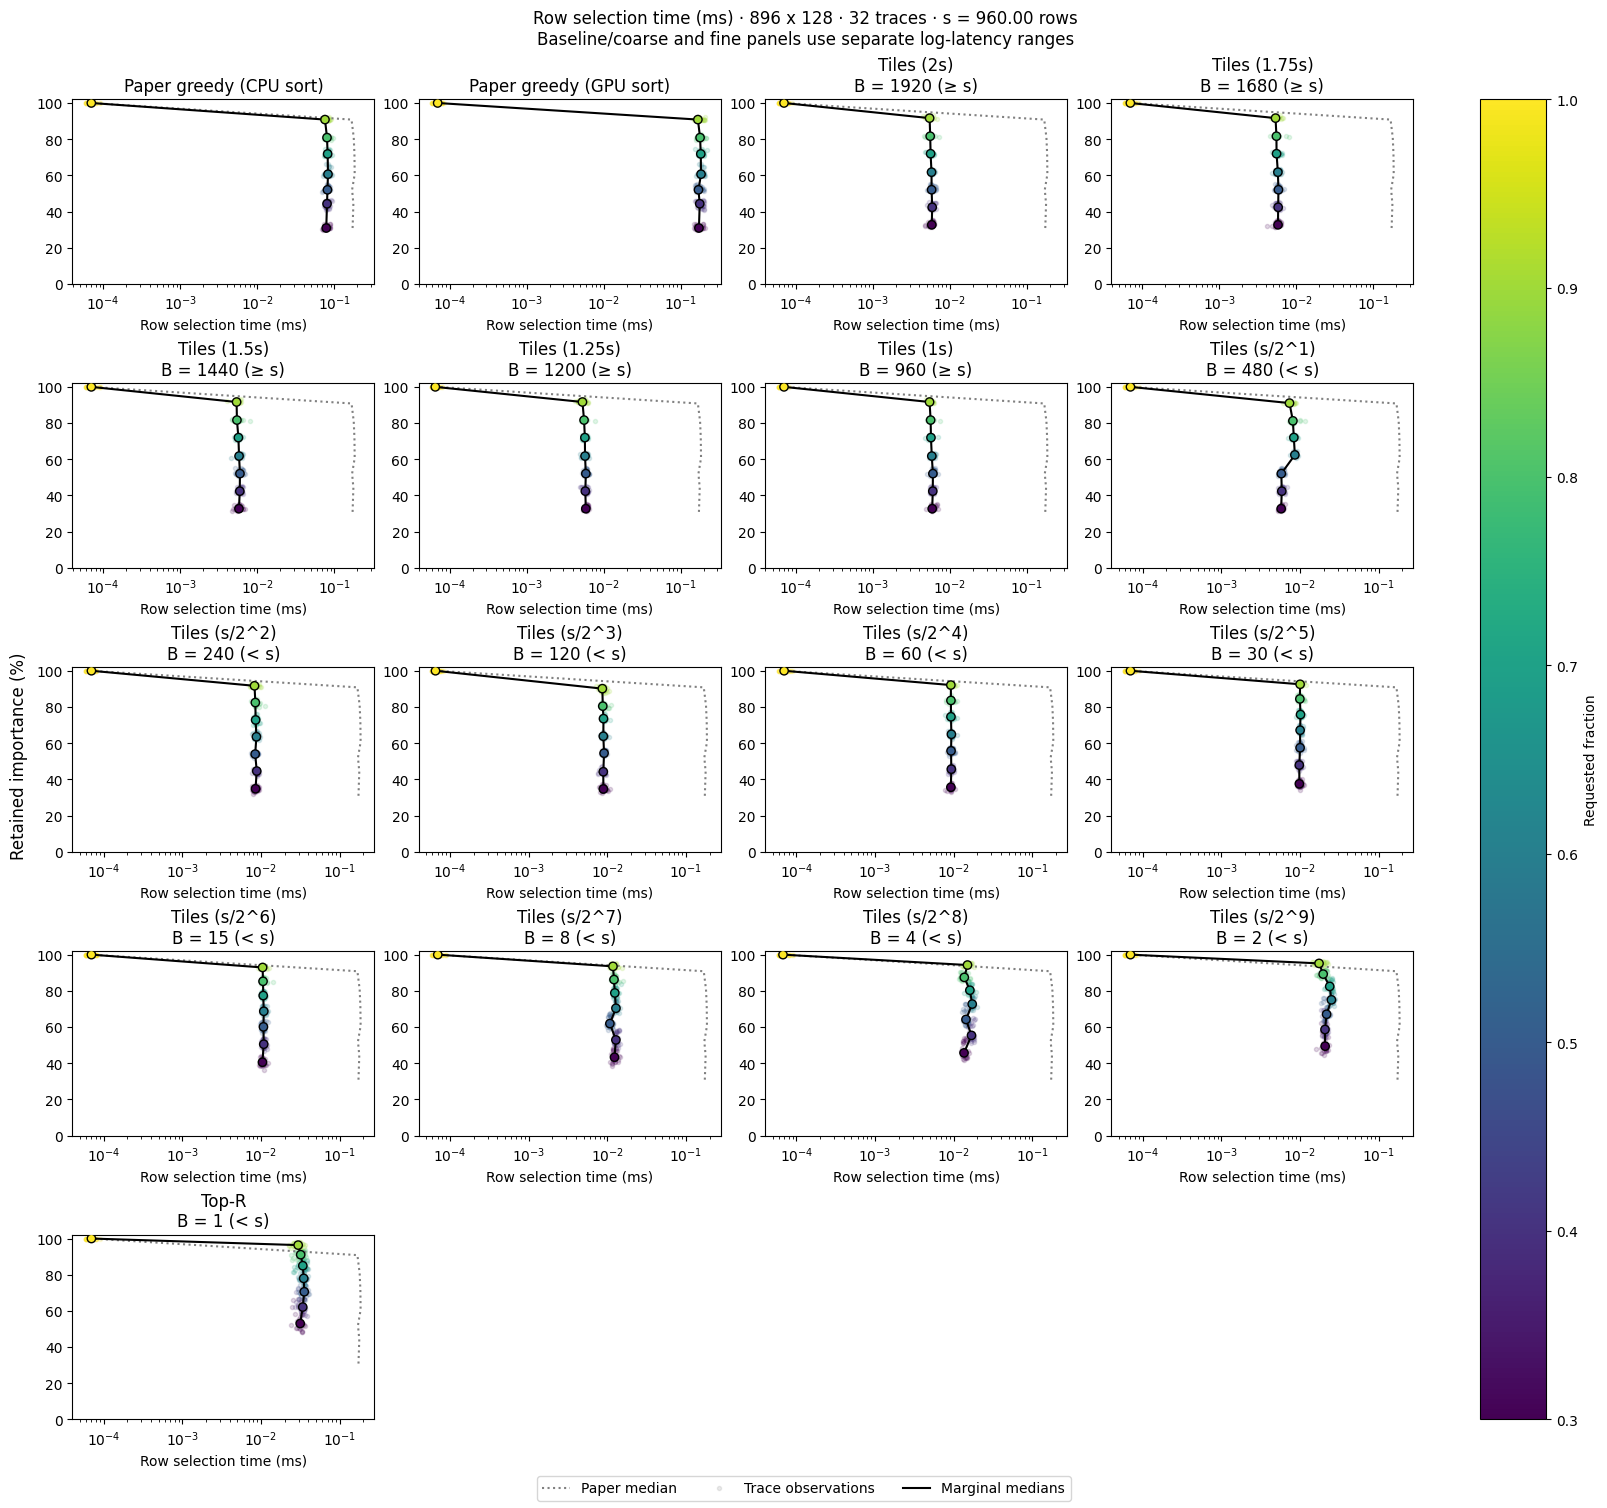

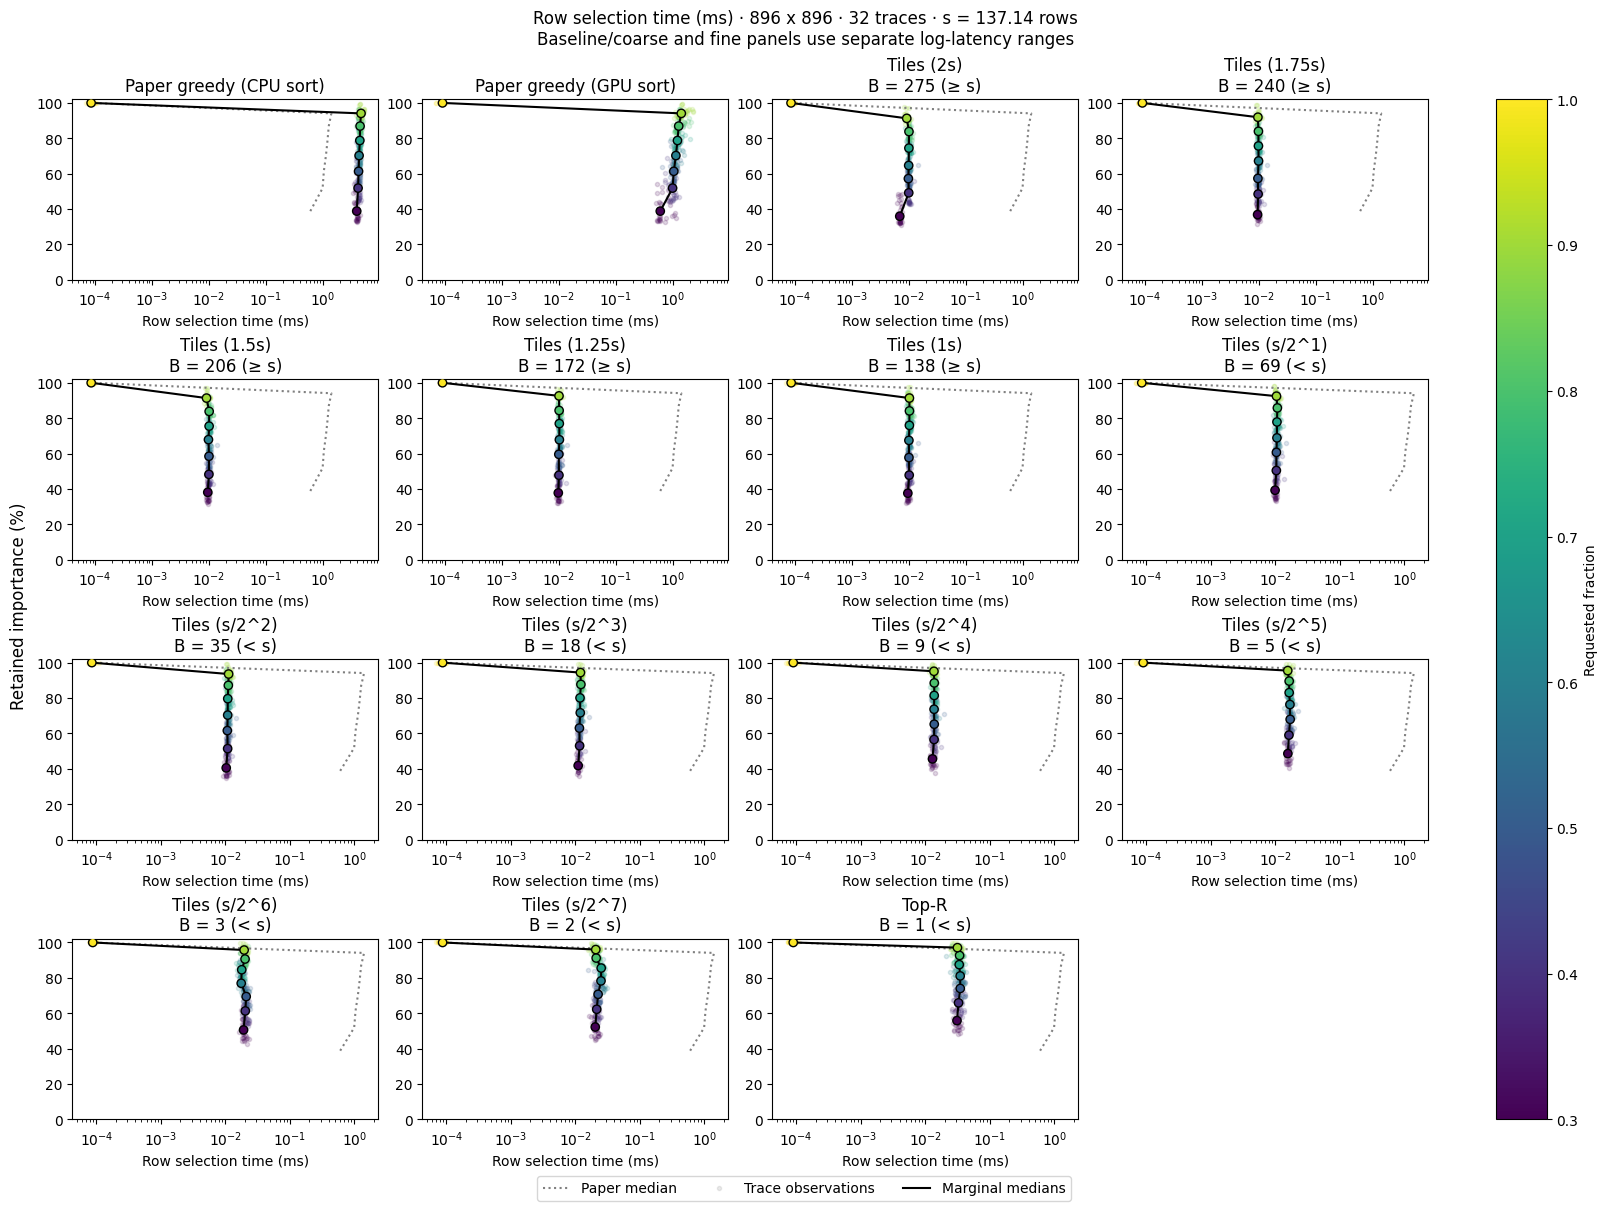

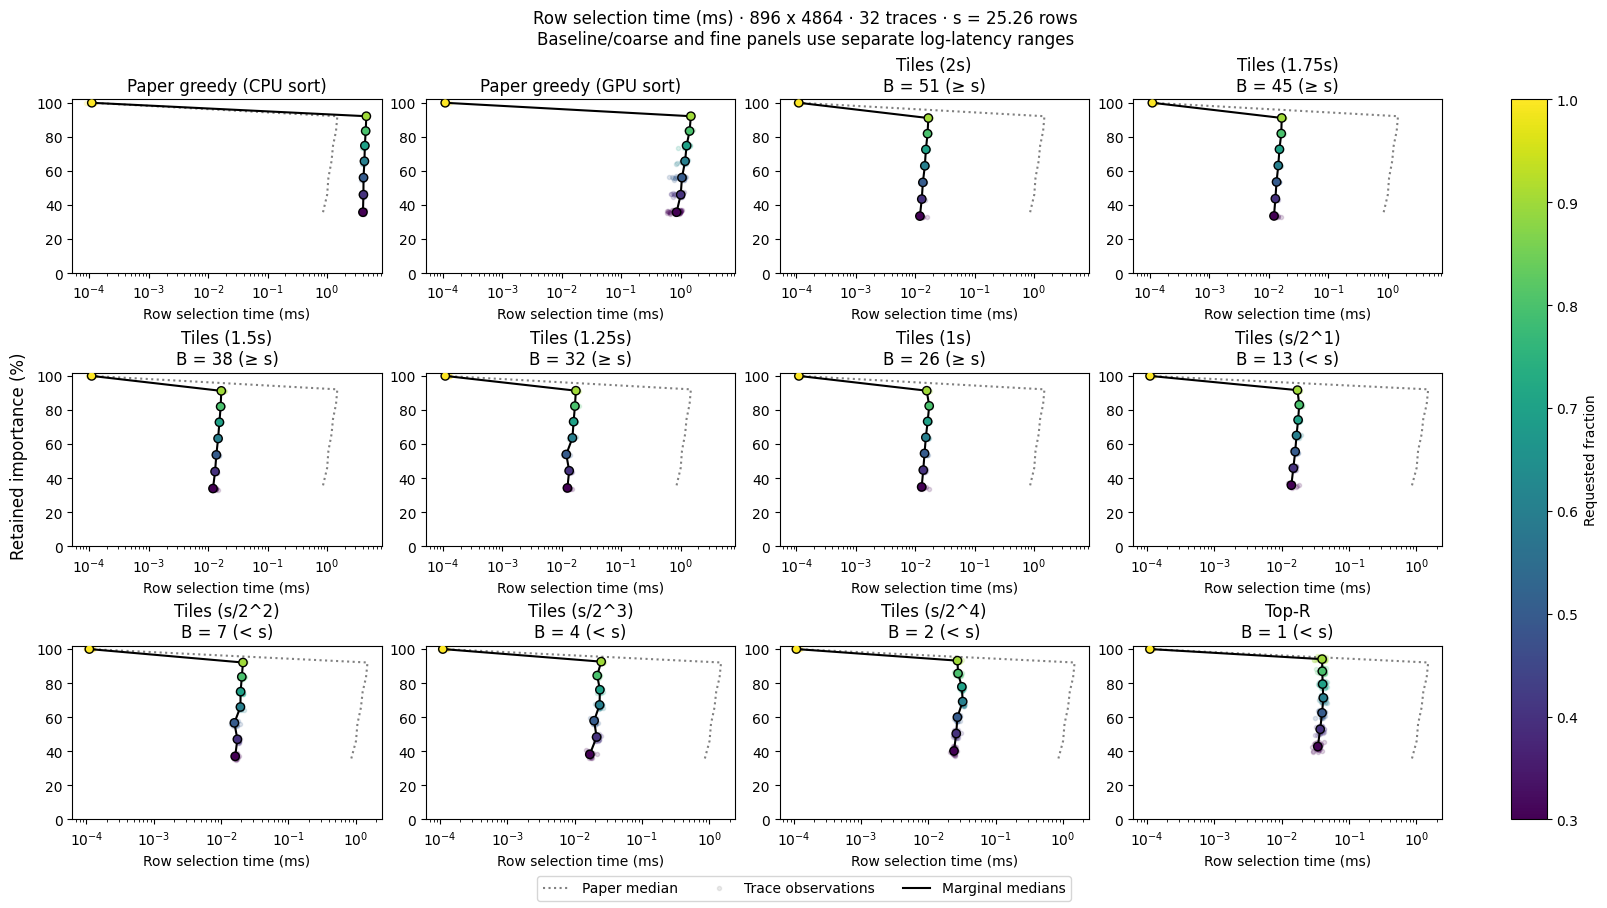

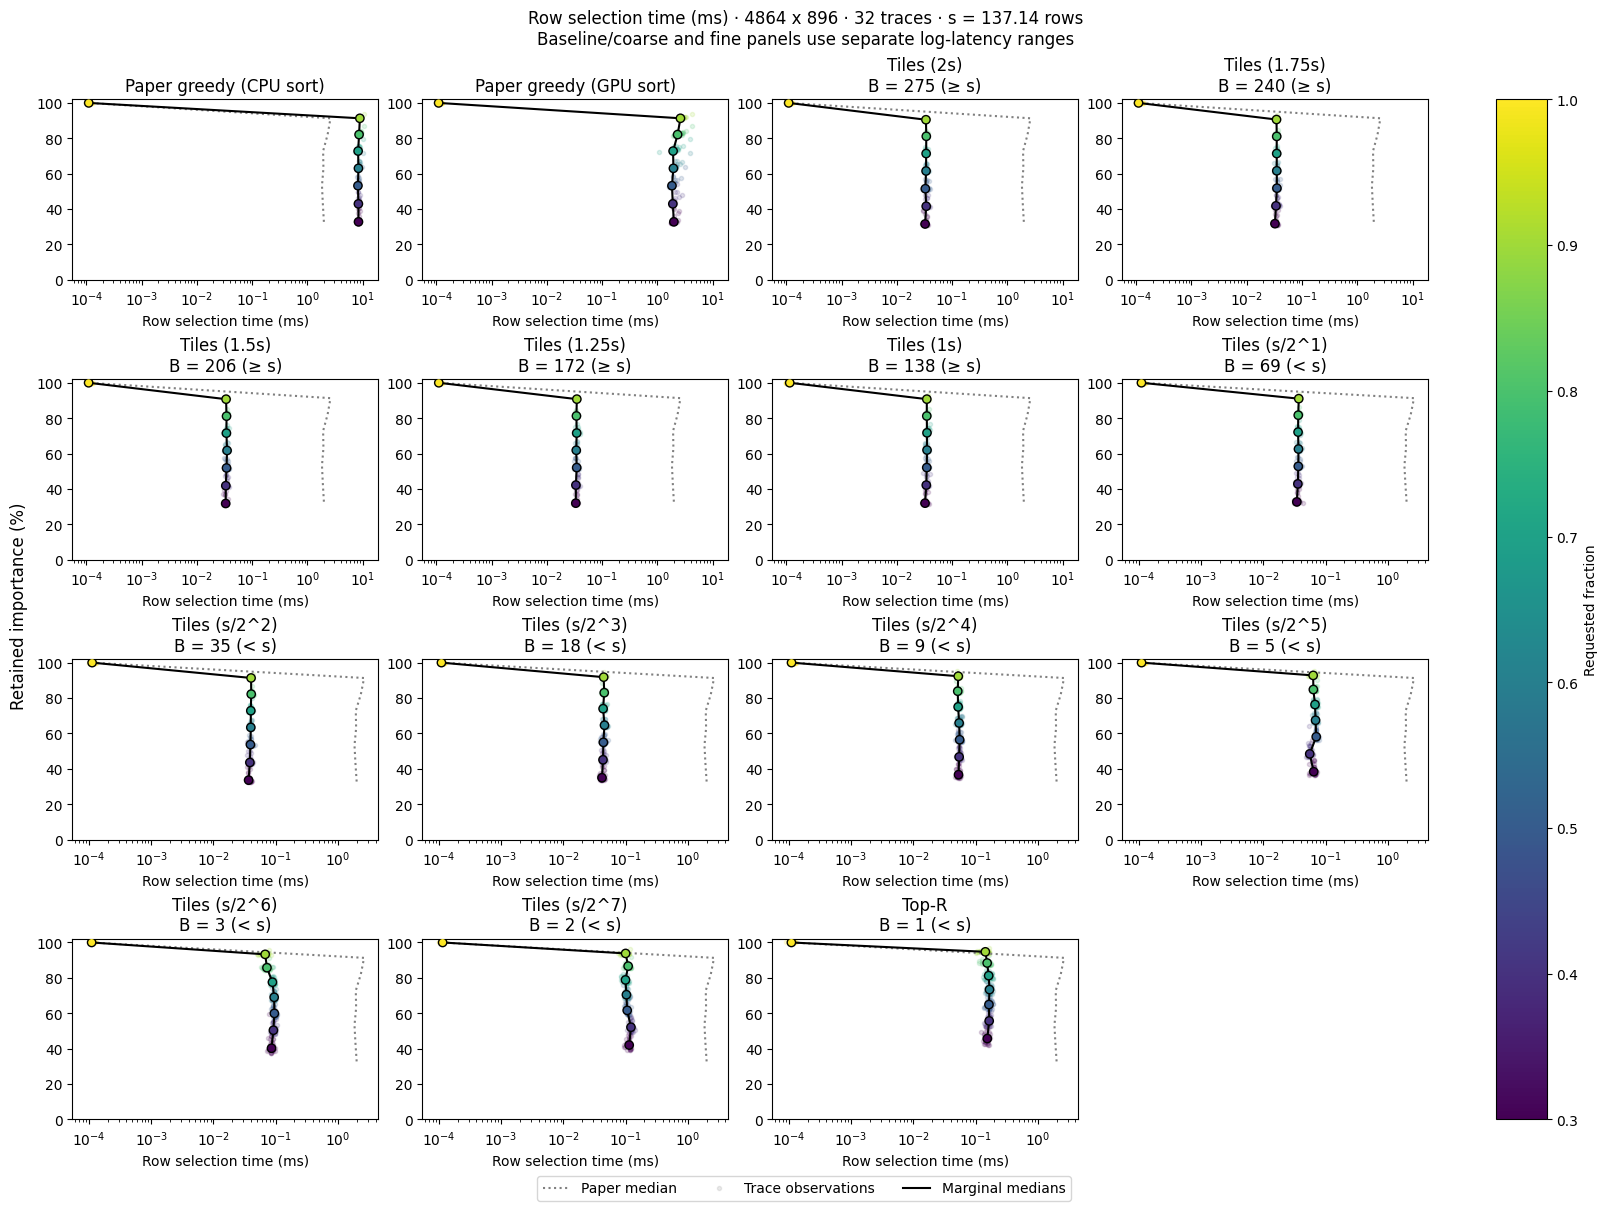

In [59]:
for result in points.values():
    fig = draw_shape(result, "selection_ms")

    plt.show()
    plt.close(fig)

### 3.2 Reader I/O time

Native read/thread interval, after the selected row mask is available.

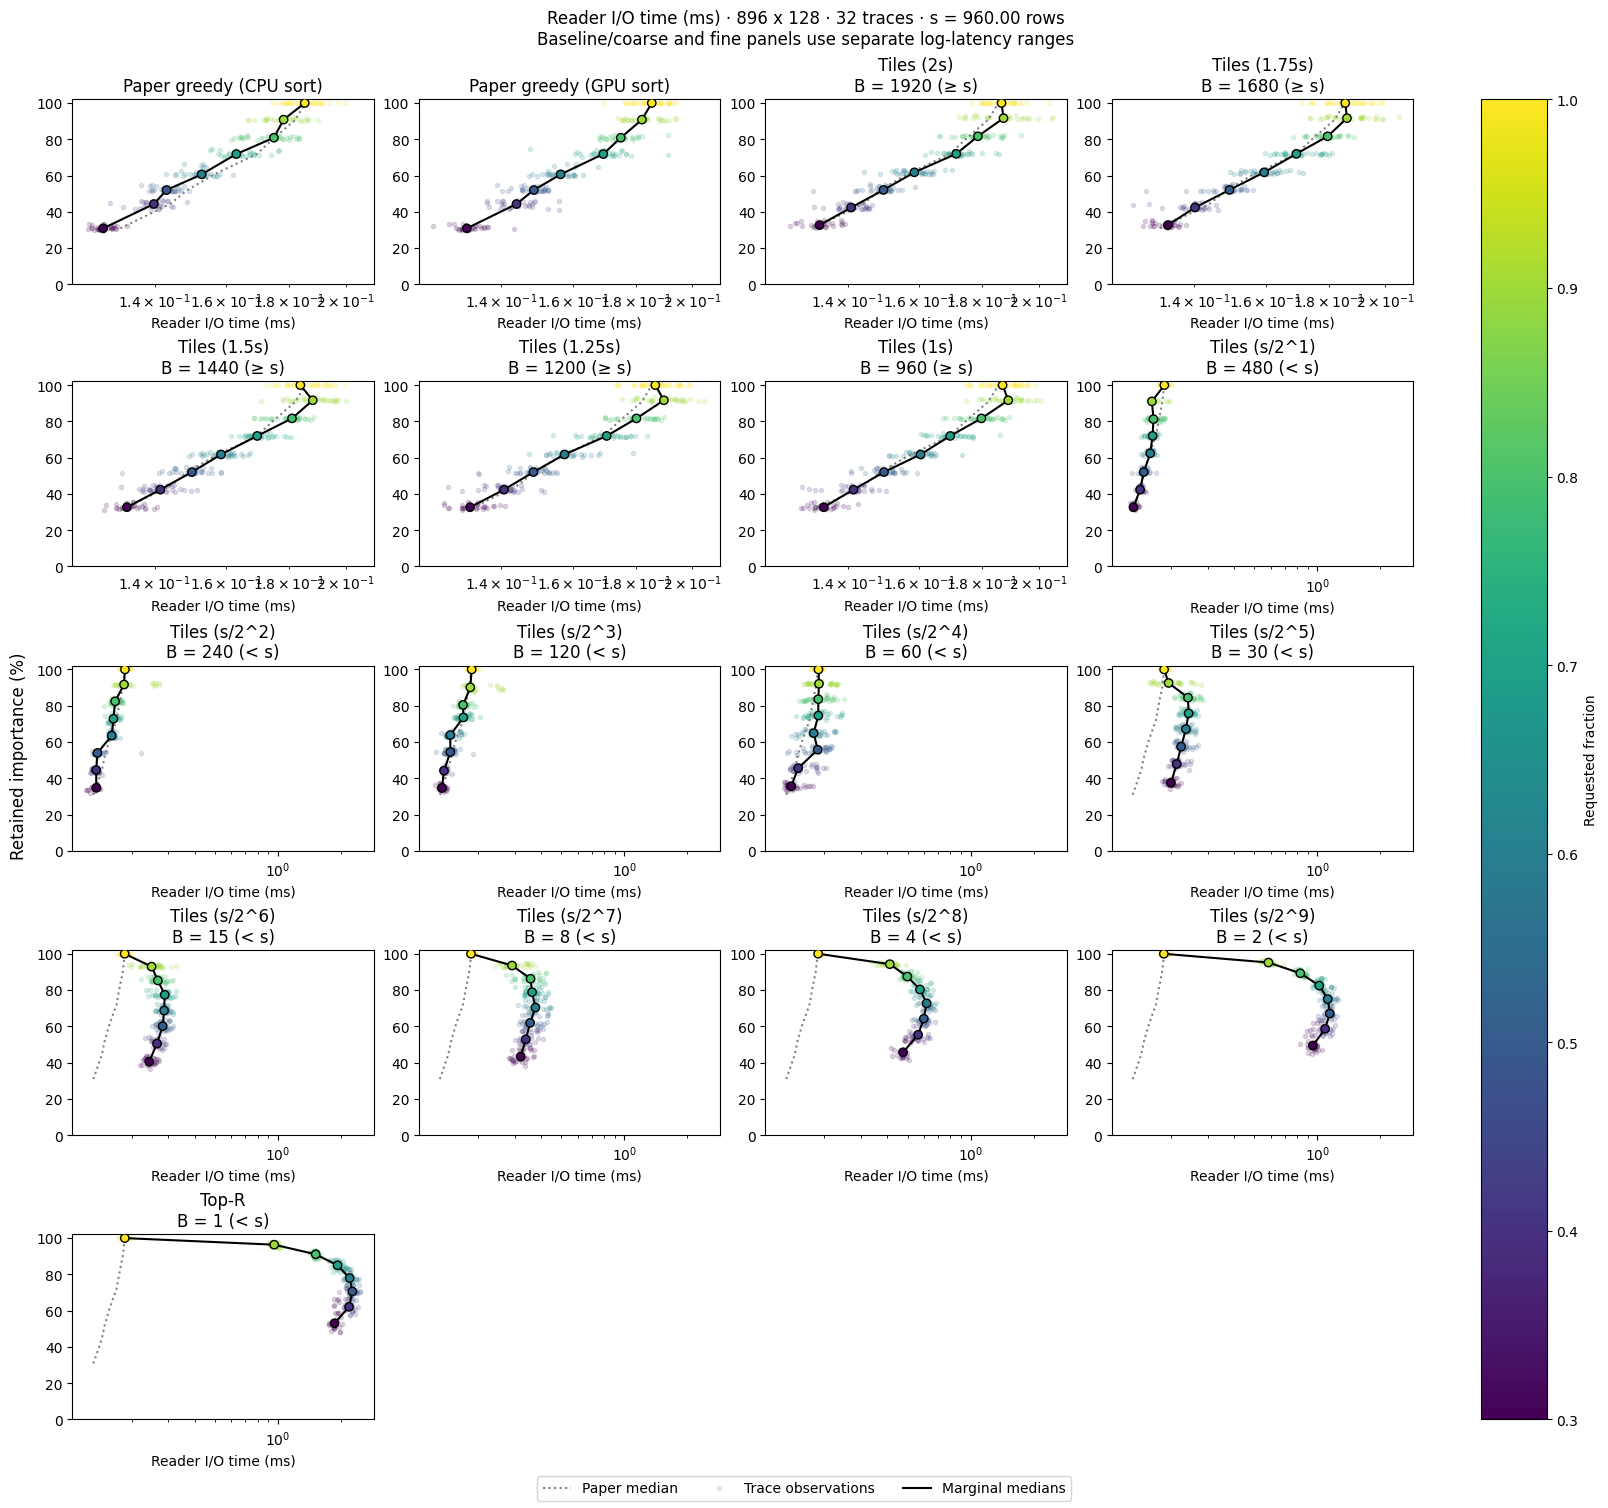

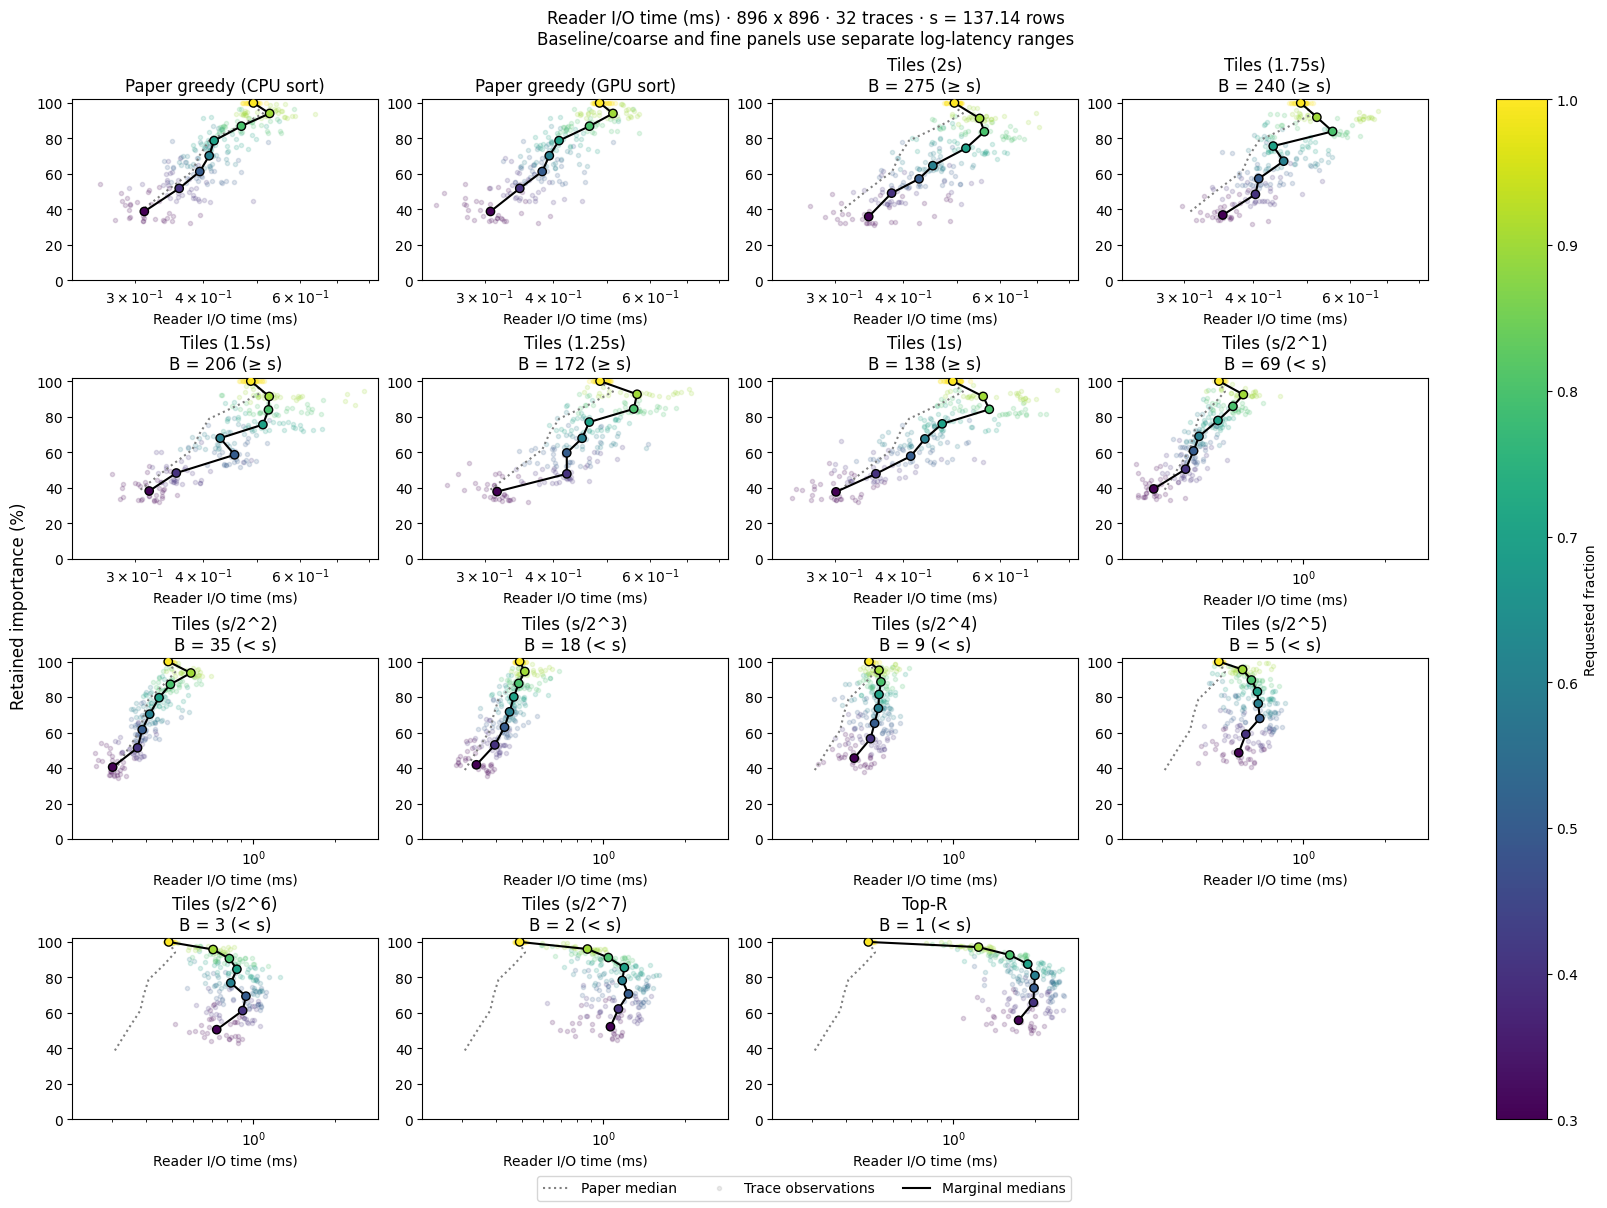

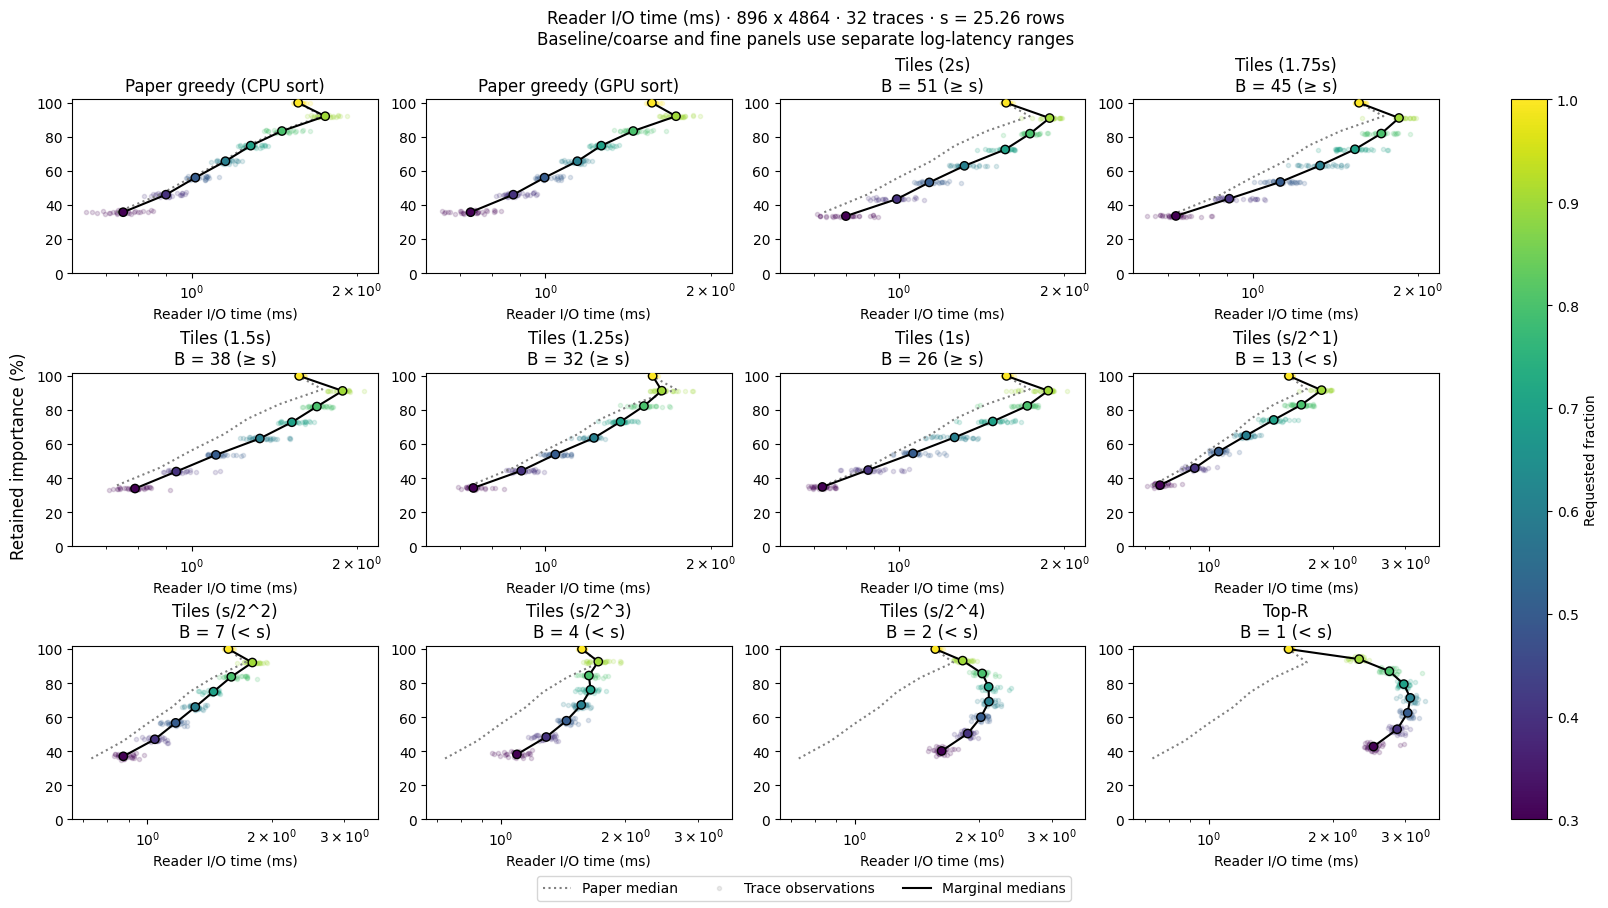

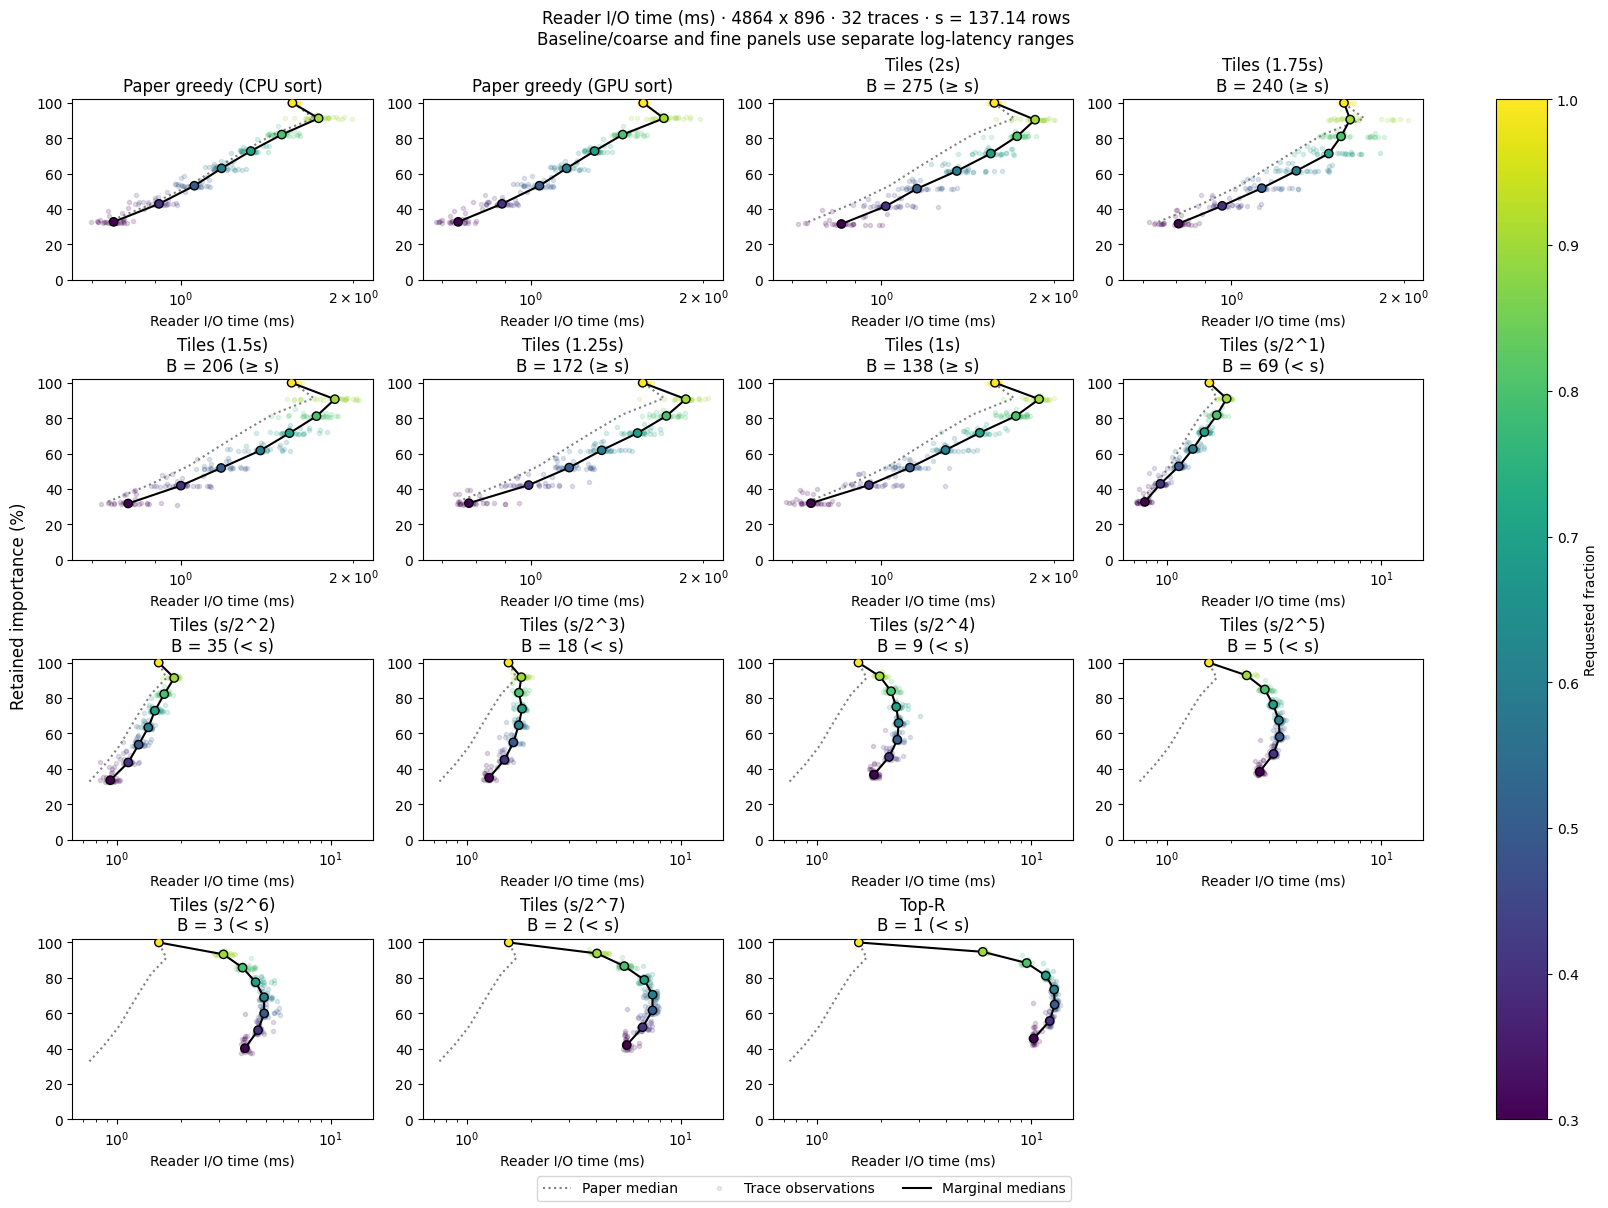

In [60]:
for result in points.values():
    fig = draw_shape(result, "io_ms")

    plt.show()
    plt.close(fig)

### 3.3 Selection and read wall time

Total measured interval, including selection, reader I/O, and read preparation.

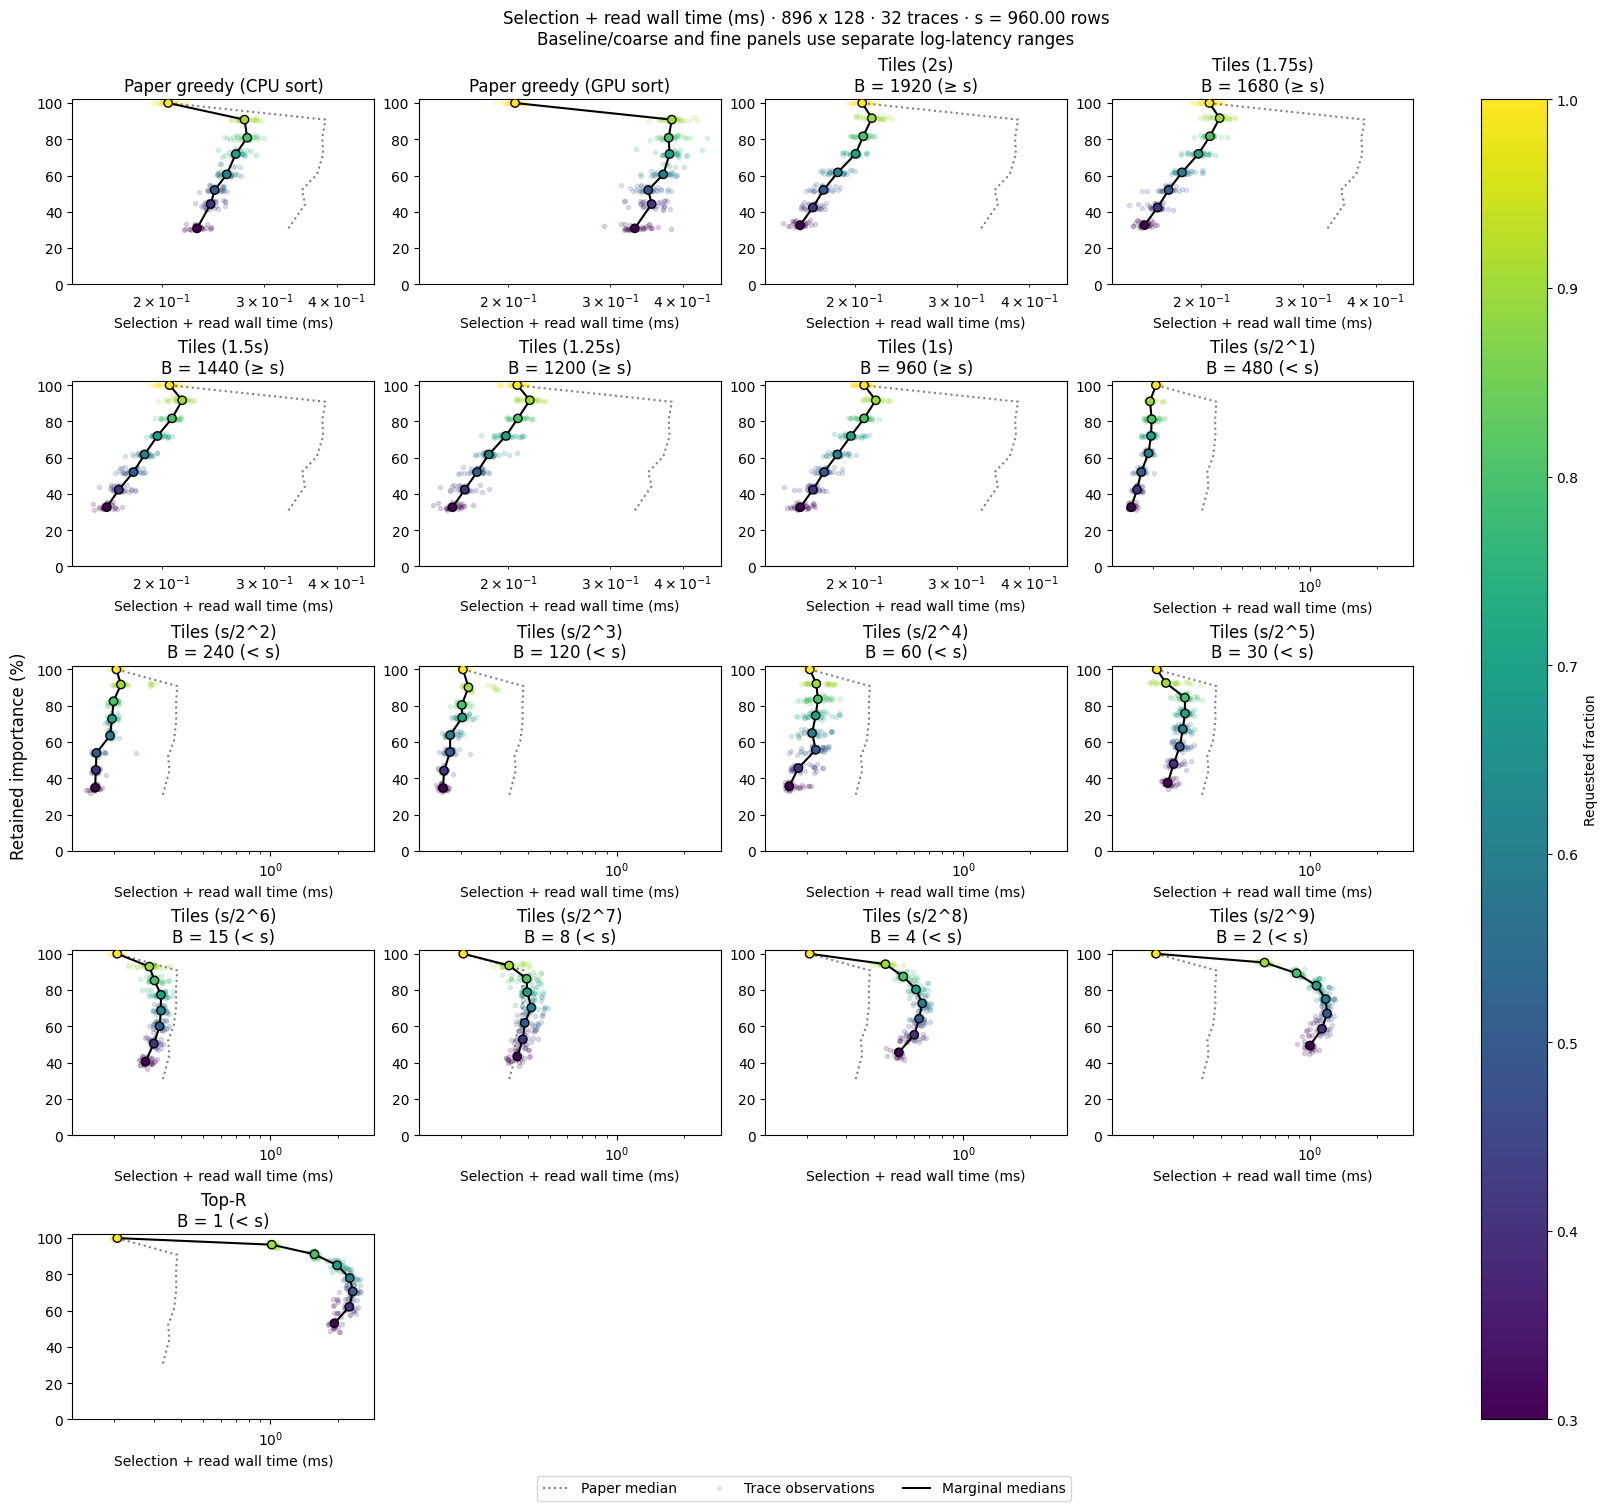

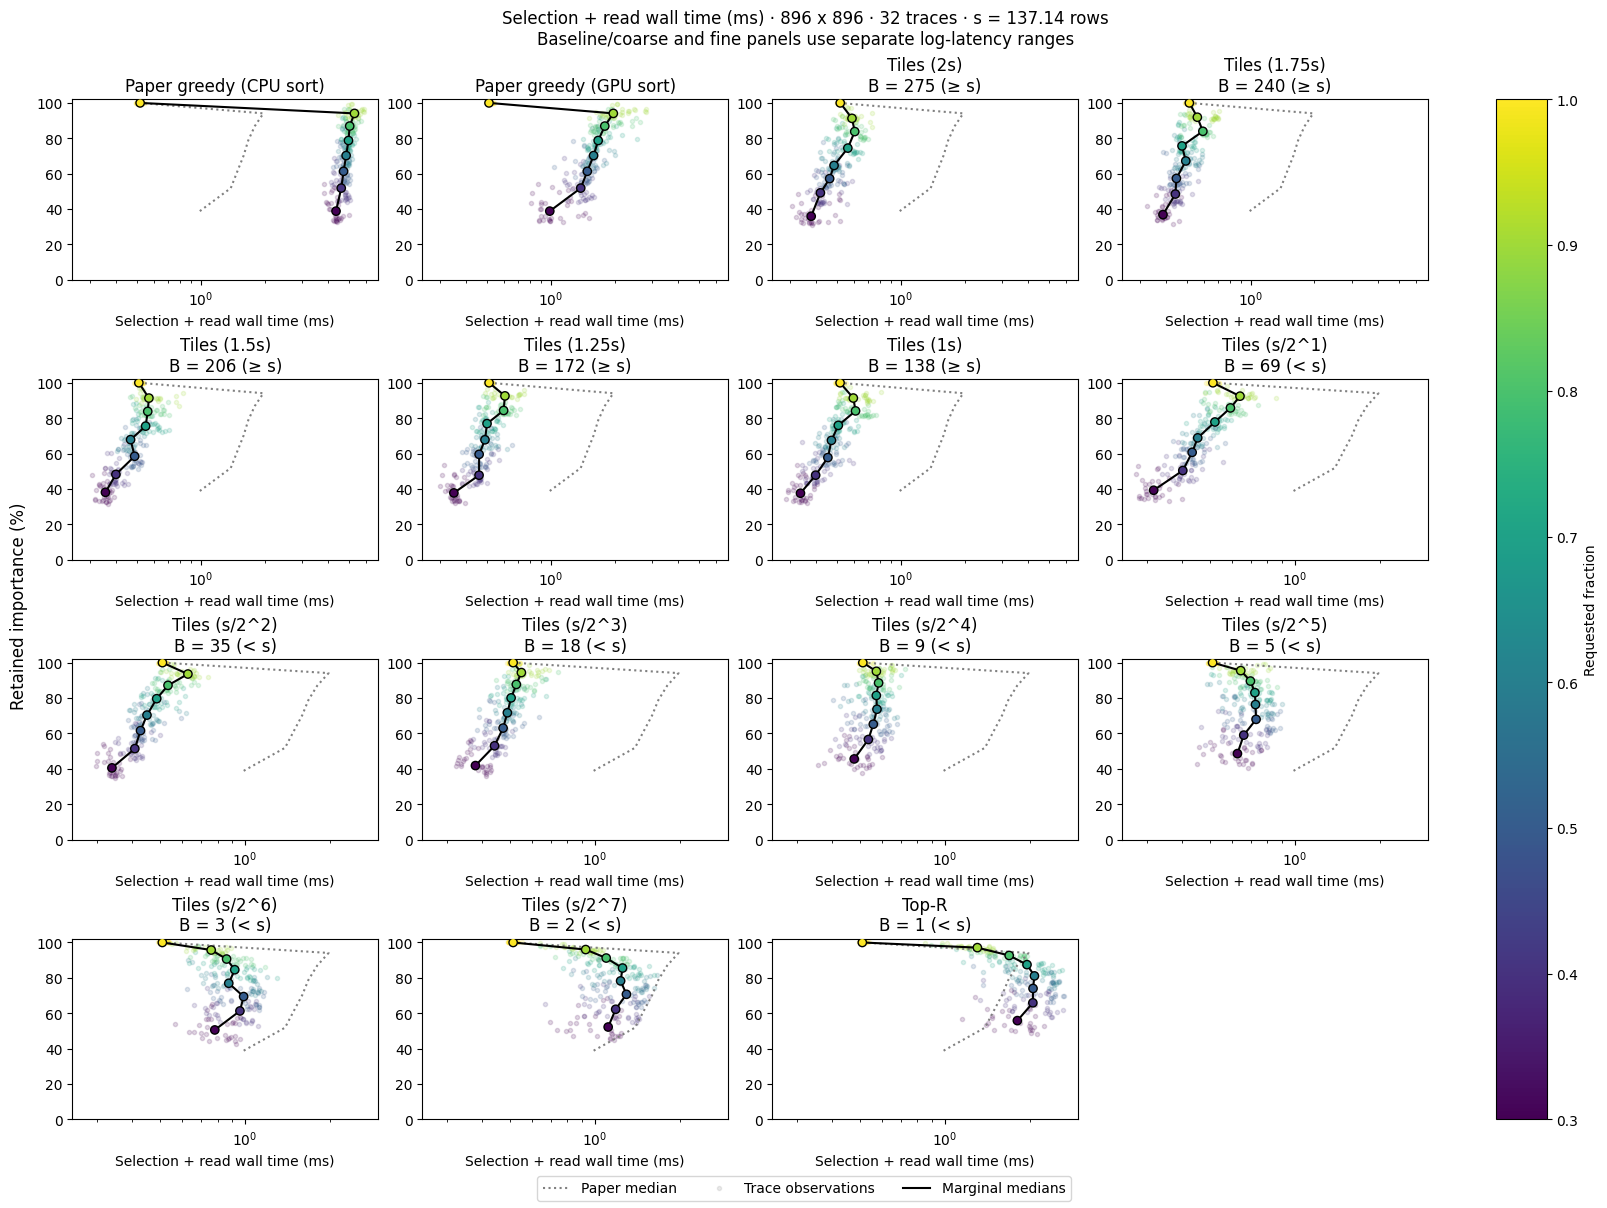

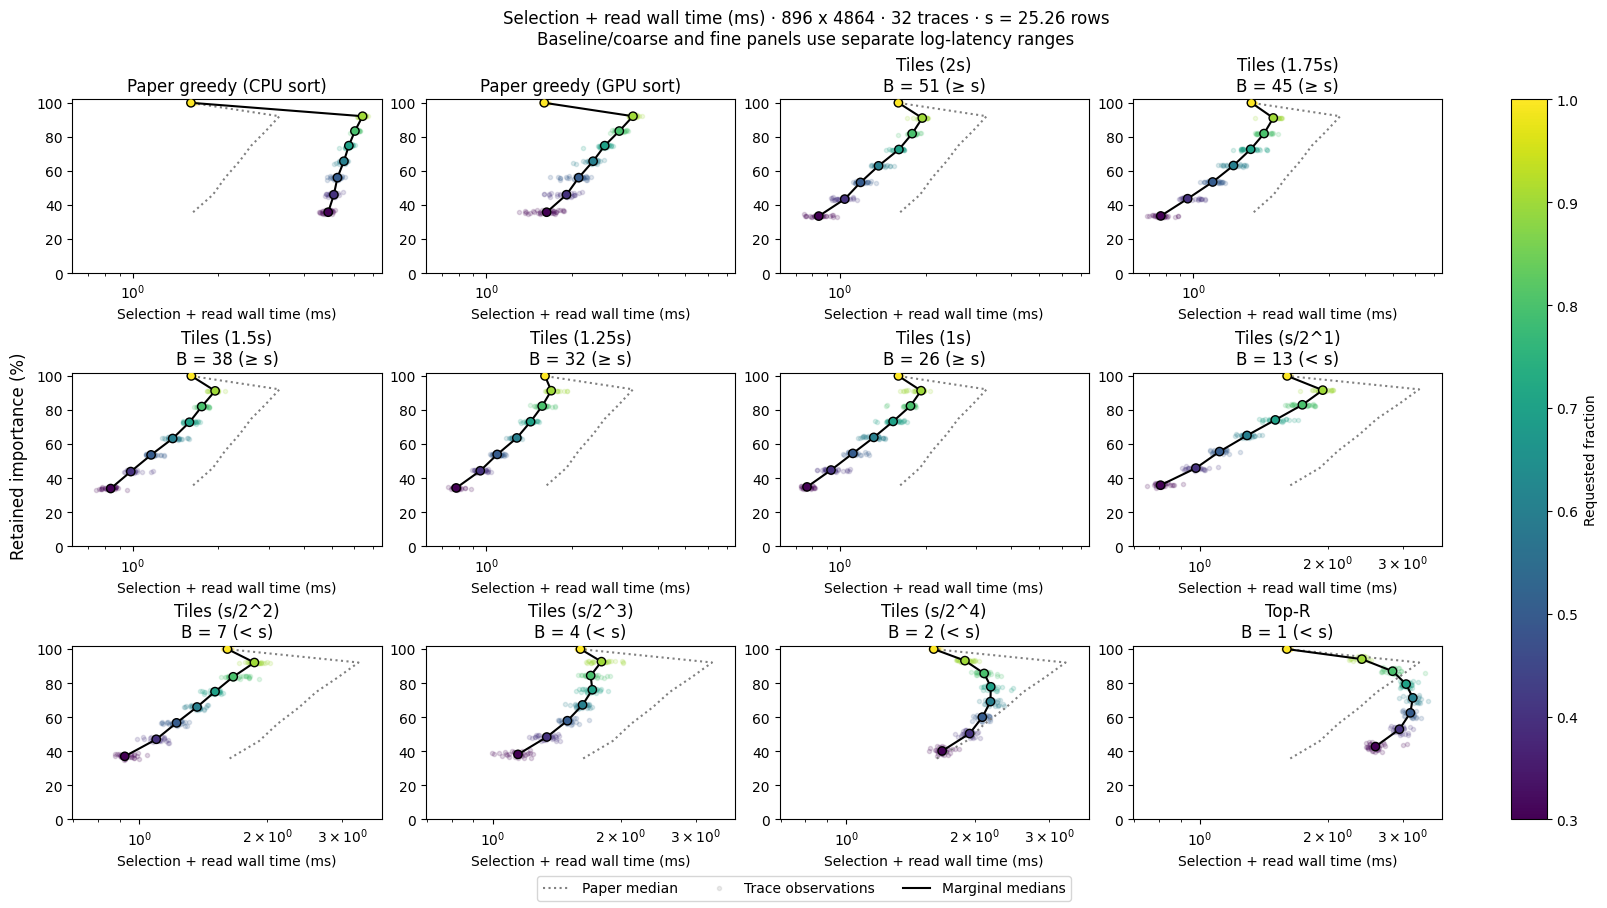

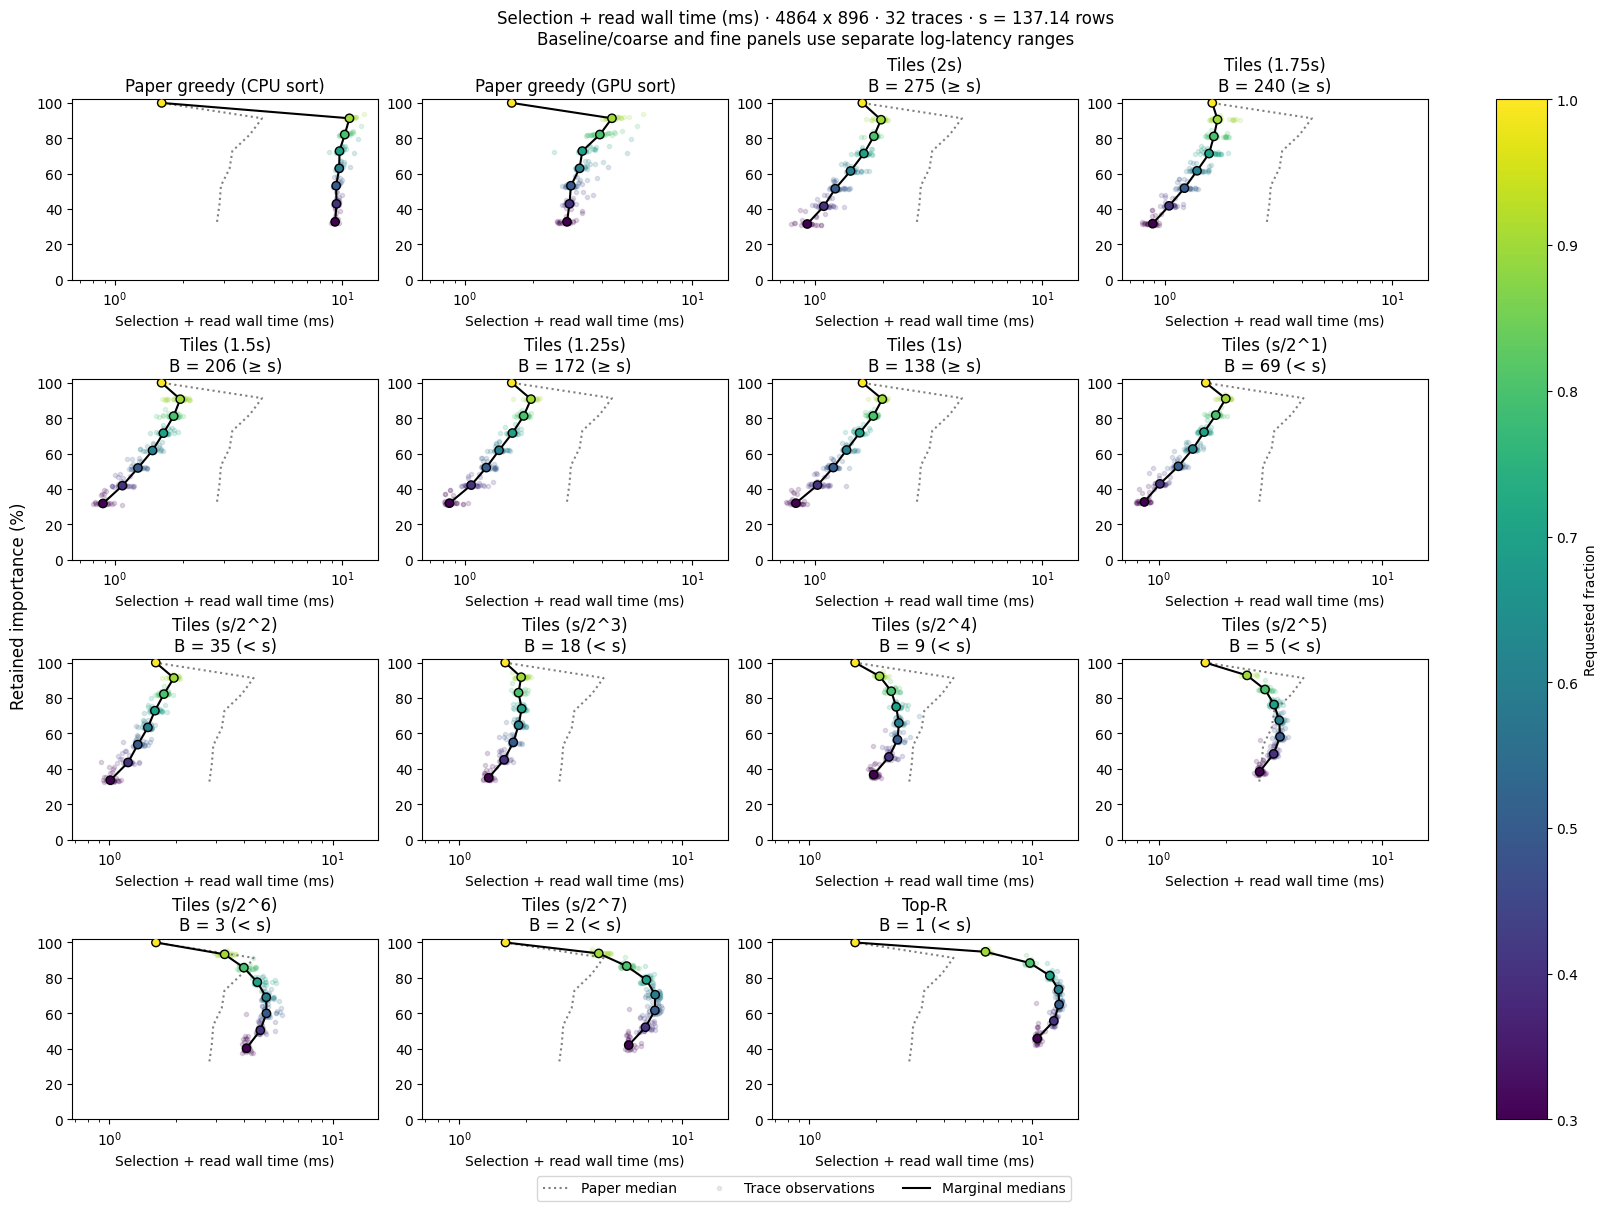

In [61]:
for result in points.values():
    fig = draw_shape(result, "wall_ms")

    plt.show()
    plt.close(fig)

## 4. Paired differences

Subtract Paper's value within each trace and requested budget. For each shape
and method, report the median over all trace–budget pairs, including full selection.
Keep selection, I/O, and wall differences in separate columns.
Negative time differences indicate faster execution; importance differences
are in percentage points.

Pairing fixes the requested budget. Selected row count and retained importance
may differ between methods.

In [62]:
records = []

for result in points.values():
    n, d     = result.shape
    baseline = result.methods[PAPER]

    for name, method in result.methods.items():
        if name == PAPER:
            continue

        differences = method.difference_from(baseline)
        median      = differences.median()

        records.append({
            "n"                  : n,
            "d"                  : d,
            "method"             : name,
            "tile_width"         : method.tile_width,
            "delta_selection_ms" : median.selection_ms,
            "delta_io_ms"        : median.io_ms,
            "delta_wall_ms"      : median.wall_ms,
            "delta_retained_pp"  : median.retained,
        })

comparisons = pd.DataFrame(records)
comparisons = comparisons.set_index(["n", "d", "method"])
comparisons.round(4)

tile_width  delta_selection_ms  \
n    d    method                                                    
896  128  Paper greedy (CPU sort)         NaN             -0.0949   
          Tiles (2s)                   1920.0             -0.1688   
          Tiles (1.75s)                1680.0             -0.1685   
          Tiles (1.5s)                 1440.0             -0.1689   
          Tiles (1.25s)                1200.0             -0.1685   
          Tiles (1s)                    960.0             -0.1684   
          Tiles (s/2^1)                 480.0             -0.1673   
          Tiles (s/2^2)                 240.0             -0.1660   
          Tiles (s/2^3)                 120.0             -0.1655   
          Tiles (s/2^4)                  60.0             -0.1652   
          Tiles (s/2^5)                  30.0             -0.1648   
          Tiles (s/2^6)                  15.0             -0.1637   
          Tiles (s/2^7)                   8.0             -0.1622   
          Tiles (s/2^8)                   4.0             -0.1595   
          Tiles (s/2^9)                   2.0             -0.1531   
          Top-R                           1.0             -0.1421   
     896  Paper greedy (CPU sort)         NaN              3.1340   
          Tiles (2s)                    275.0             -1.0669   
          Tiles (1.75s)                 240.0             -1.0678   
          Tiles (1.5s)                  206.0             -1.0665   
          Tiles (1.25s)                 172.0             -1.0667   
          Tiles (1s)                    138.0             -1.0674   
          Tiles (s/2^1)                  69.0             -1.0666   
          Tiles (s/2^2)                  35.0             -1.0666   
          Tiles (s/2^3)                  18.0             -1.0648   
          Tiles (s/2^4)                   9.0             -1.0634   
          Tiles (s/2^5)                   5.0             -1.0599   
          Tiles (s/2^6)                   3.0             -1.0575   
          Tiles (s/2^7)                   2.0             -1.0527   
          Top-R                           1.0             -1.0427   
     4864 Paper greedy (CPU sort)         NaN              3.0885   
          Tiles (2s)                     51.0             -1.1123   
          Tiles (1.75s)                  45.0             -1.1124   
          Tiles (1.5s)                   38.0             -1.1121   
          Tiles (1.25s)                  32.0             -1.1135   
          Tiles (1s)                     26.0             -1.1112   
          Tiles (s/2^1)                  13.0             -1.1092   
          Tiles (s/2^2)                   7.0             -1.1106   
          Tiles (s/2^3)                   4.0             -1.1072   
          Tiles (s/2^4)                   2.0             -1.0972   
          Top-R                           1.0             -1.0844   
4864 896  Paper greedy (CPU sort)         NaN              6.3270   
          Tiles (2s)                    275.0             -1.9319   
          Tiles (1.75s)                 240.0             -1.9333   
          Tiles (1.5s)                  206.0             -1.9347   
          Tiles (1.25s)                 172.0             -1.9339   
          Tiles (1s)                    138.0             -1.9333   
          Tiles (s/2^1)                  69.0             -1.9323   
          Tiles (s/2^2)                  35.0             -1.9286   
          Tiles (s/2^3)                  18.0             -1.9244   
          Tiles (s/2^4)                   9.0             -1.9147   
          Tiles (s/2^5)                   5.0             -1.9081   
          Tiles (s/2^6)                   3.0             -1.8810   
          Tiles (s/2^7)                   2.0             -1.8552   
          Top-R                           1.0             -1.8024   

                                   delta_io_ms  delta_wall_ms  \
n    d    method                    